<a href="https://colab.research.google.com/github/nika19du/Math-Music-Project/blob/main/Math_Music_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# The Mathematics behind music: notes, intervals and chords

**Math concepts for developers** - course project (work in progress)

> this notebook is an evloving investigation. The experiments and conclusions will be expanded as the project develops.

## 1. Introduction
Music can be described using mathematical structures. The twelve pitch classes is Western equal temperament form a repeating cycle, intervals can be represented as differences and chords can be constructed using fixed semitone patterns.

**Research question**: How can numerical and vector representations help us construct analyze and transform melodies and chords?

**Objectives**:
1. Represent notes and pitch classes numerically.
2. Calculate melodic intervals using vector and matrix operations.
3. Construct major and minor triads from interval patterns.
4. Validate the mathematical models with Python experiments

**Scope and assumptions:** we use twelve-tone qual-tempered system (12-TET). We focus on pitch and ordered note sequences, not rhythm, dynamics, timbre or full harmonic analysis. Pitch-class values discard octave informtation. In this notebook, note names use sharps for simplicity, enharmonic spelling depend on musical context.

## 2. Mathematical Foundations: Semitones and Pitch Classes

In 12-TET, an ocatave contains **12 equal semitone steps**. We encode the pitch classes using integers from $0$ to $11$:

| Note | C | C♯ | D | D♯ | E | F | F♯ | G | G♯ | A | A♯ | B |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| Pitch class | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 | 11 |

Becuase the pitch classes repeat every octave, we use **modular arithmetic**:
$$ p = n \bmod 12. $$

For example, $12\bmod 12=0 $ and $14\bmod 12=2$. Thus pitch classes $0$ and $12$ both represent C, although the latter is one octave higher in our semitone coordinate system.

**Important distinction:** A pitch class (modulo 12) is not the same as a pitch height. For computing directed melodic intervals across octaves, we retain integer semitone heights without reducing them modulo 12.

In 12-TET, the frequency ration of two pitches separated by $k$ semitones is:
$$\frac{f_2}{f_1}=2^{k/12}.$$

For $k=12$ this becomes $f_2=2f_1$ the octave relationship.


In [1]:
 NOTE_NAMES = ["C", "C#", "D", "D#", "E", "F", "F#", "G", "G#", "A", "A#", "B"]

def pitch_class(semitone_height: int) -> int:
  """
  Return the pitch class(0..11) of an integer semitone height.
  """
  return semitone_height  % 12

def note_name(semitone_height: int) -> str:
  """
  Return a simplified sharp-based note name (without octave).
  """
  return NOTE_NAMES[pitch_class(semitone_height)]

for height in [0, 4, 7, 9, 12, 14]:
    print(f"height={height:2d}  pitch_class={pitch_class(height):2d}  note={note_name(height)}")

height= 0  pitch_class= 0  note=C
height= 4  pitch_class= 4  note=E
height= 7  pitch_class= 7  note=G
height= 9  pitch_class= 9  note=A
height=12  pitch_class= 0  note=C
height=14  pitch_class= 2  note=D


## 3. Melodies as Vectors and Intervals as Differences

Consider four consecutive note heights represented by the vector

$$\mathbf{m}=\begin{bmatrix}0\\4\\7\\9\end{bmatrix}.$$

Their **successive directed intervals** are $4-0=4$, $7-4=3$ and $9-7=2$ semiteones. We can compute these intervals using the matrix

$$D=\begin{bmatrix}-1&1&0&0\\0&-1&1&0\\0&0&-1&1\end{bmatrix}.$$

Then

$$D\mathbf{m}=\begin{bmatrix}4\\3\\2\end{bmatrix}.$$

This matrix represents a linear transformation
$D:\mathbb{R}^{4}\rightarrow\mathbb{R}^{3}$.
It maps four note heights to three adjacent differences. In general, a sequence of $n$ notes produces $n-1$ successive intervals.

**Why the starting note matters.** Two melodiec can have the same intervals:
$$\mathbf{m}_1=(0,4,7,9)^T,\qquad\mathbf{m}_2=(5,9,12,14)^T.$$

Both give

$D\mathbf{m}_1=D\mathbf{m}_2=(4,3,2)^T$. Their difference is $(5,5,5,5)^T$, which is mapped to zero. Therefore, the intervals alone do not determine the absolute starting height.

In [2]:
import numpy as np

melody = np.array([0, 4, 7, 9], dtype = int)
D = np.array([
    [-1, 1, 0, 0],
    [0, -1, 1, 0],
    [0, 0, -1, 1]
], dtype = int)

intervals_matrix = D @ melody
intervals_numpy = np.diff(melody)

print("Melody: ", melody)
print("Intervals from matrix: ", intervals_matrix)
print("Intervals from np.diff: ", intervals_numpy)
assert np.array_equal(intervals_matrix, intervals_numpy)
assert np.array_equal(intervals_matrix, [4, 3, 2])

Melody:  [0 4 7 9]
Intervals from matrix:  [4 3 2]
Intervals from np.diff:  [4 3 2]


In [3]:
def reconstruct_melody(start_height: int, intervals) -> np.ndarray:
  """
  Reconstruct integer note height from the first height and directed intervals.
  """
  intervals = np.asarray(intervals, dtype = int)
  return np.concatenate(([start_height], start_height + np.cumsum(intervals)))

original = reconstruct_melody(0, [4, 3, 2])
transposed = reconstruct_melody(5, [4, 3, 2])

print("Starting at C: ", original, [note_name(x) for x in original])
print("Starting at F: ", transposed, [note_name(x) for x in transposed])

assert np.array_equal(np.diff(original), np.diff(transposed))

Starting at C:  [0 4 7 9] ['C', 'E', 'G', 'A']
Starting at F:  [ 5  9 12 14] ['F', 'A', 'C', 'D']


## 4. Chords as Semitone Patterns

A **triad** contains three chord tones. In its root-position construction, a **major triad** has semitone offsets $(0,4,7)$
relative to the root, whereas a **minor triad** has offsets $(0,3,7)$.

For a root height $r$:

$$\mathbf{c}_{\mathrm{major}}(r)=(r,r+4,r+7),$$

$$\mathbf{c}_{\mathrm{minor}}(r)=(r,r+3,r+7).$$

For example, C major is C-E-G (pitch classes $0,4,7$, while C minor is C-D#-G in our simplified sharp-based naming

These formulates describe one **voicing in root position**, not every possibe arrangement of a chord. Chord inversions and octave doublings will be considered later.

In [4]:
TRIAD_PATTERNS = {
    "major": np.array([0, 4, 7], dtype=int),
    "minor": np.array([0, 3, 7], dtype=int)
}

def build_triad(root_height: int, quality: str="major") -> np.ndarray:
  """
  Build a root-position triad using semitone offsets.
  """
  if quality not in TRIAD_PATTERNS:
    raise ValueError("Quality must be 'major' or 'minor'")
  return root_height + TRIAD_PATTERNS[quality]

for quality in ["major", "minor"]:
    chord = build_triad(0, quality)
    print(f"C {quality}: {chord} => {[note_name(x) for x in chord]}")

assert np.array_equal(build_triad(0, "major"), [0, 4, 7])
assert np.array_equal(build_triad(0, "minor"), [0, 3, 7])

C major: [0 4 7] => ['C', 'E', 'G']
C minor: [0 3 7] => ['C', 'D#', 'G']


## 5. Initial Experiment: Transposition preserves intervals

**Hypothesis**: Adding a constant number of semitones to every note in a melody does not change the successive directed intervals.

For a melody vector \mathbf{m}\in\mathbb{R}^{n}$ and a constant $k$, define transposition by

$$T_k(\mathbf{m})=\mathbf{m}+k\mathbf{1},$$

where $\mathbf{1}$ is the all-ones vector. Since $D\mathbf{1}=\mathbf{0}$,

$$D(T_k(\mathbf{m}))=D\mathbf{m}+kD\mathbf{1}=D\mathbf{m}.$$

Thus **interval preservation follows algebraically**. The transposition map $T_k$ is an affine transformation (unless $k=0$), not a linear map in the strict sence. The difference map $D$ is linear.

We now verify the result computationally for several transpositions

In [5]:
base_melody = np.array([0, 4, 7, 9], dtype=int)
base_intervals = np.diff(base_melody)

for shift in [-7, -2, 0, 5, 12]:
    shifted = base_melody+shift
    result = np.diff(shifted)
    assert np.array_equal(result, base_intervals)
    print(f"shift={shift:>3}: notes={shifted.tolist()}, intervals={result.tolist()}")

print("All tested transpositions preserve the directed intervals.")

shift= -7: notes=[-7, -3, 0, 2], intervals=[4, 3, 2]
shift= -2: notes=[-2, 2, 5, 7], intervals=[4, 3, 2]
shift=  0: notes=[0, 4, 7, 9], intervals=[4, 3, 2]
shift=  5: notes=[5, 9, 12, 14], intervals=[4, 3, 2]
shift= 12: notes=[12, 16, 19, 21], intervals=[4, 3, 2]
All tested transpositions preserve the directed intervals.


## 6. Next steps

**Initial findings**: A constant transposition changes absolute pitch heights but preserves successive directed intervals. The proof and Python checks agree.

**Limitations:** The representation ignores note durations, rhythm, timbre, dynamics, musical key spelling and harmonic function. The simple triad model currently covers only major and minor root-position triads.

**Planned extensions:**
- Analy chord progressions (for example: Em-C-G-D)
- Compare chord represenations and explore inversions.
- Visualize pitch-class distributions and interval patterns.
- Add a small set of musical examples, controlled experiments and final conclusion.
- Add references for music theoty and mathematical definitions.

## Referencess (to complete)
Add and cite the specific textbooks, course materials or documentation

## 7. Chord Progressions: From Individual Chords to Harmony

A **chord progressions** is an ordered sequence of chords. In this section, we study the progression **Em-C-G-D**. Each chord is a *triad* (three notes). A progression is not the same as a melody: a melody describes notes in sequence, while a progression describes how chords change over time.

We represent each root note as an integer number of semitones relative to C and each triad by a pattern of offsets:

$$\text{major}=(0,4,7),\qquad \text{minor}=(0,3,7).$$

For a root height $r$ and pattern $\mathbf{p}$, the chord is $\mathbf{c}=r\mathbf{1}+\mathbf{p}$. We use $\bmod\ 12$ to map absolute height to **pitch classes** (note names without octave information)> For simplicity the prohram display enharmonic notes using sharps(e.g., F# rather than Gb).

In [6]:
# Each pair is root pitch class, chord quality.
progression = [(4, "minor"), (0, "major"), (7, "major"), (2, "major")]
chord_symbols = ["Em", "C", "G", "D"]

def chord_pitch_classes(root: int, quality: str) -> np.ndarray:
  """
  Return three pitch classes for a root-position major/minor triad.
  """
  return (root + TRIAD_PATTERNS[quality]) % 12

for symbol, (root, quality) in zip(chord_symbols, progression):
  pcs = chord_pitch_classes(root, quality)
  print(f"{symbol:>2}: {pcs.tolist()} -> {[NOTE_NAMES[p] for p in pcs]}")

Em: [4, 7, 11] -> ['E', 'G', 'B']
 C: [0, 4, 7] -> ['C', 'E', 'G']
 G: [7, 11, 2] -> ['G', 'B', 'D']
 D: [2, 6, 9] -> ['D', 'F#', 'A']


## 8. Comparing Chords: Common Tones
Two chords can share one or more **pitch classes**. We can measure this using sets. Let $A$ and $B$ be the sets of pitch classes in two chords. Their shared tones are the **intersection**:

$$A\cap B.$$

The number of shared pitch classes is $|A\cap B|$. This is a simple, measurable feature of a chord change, **not** a complete model of how smooth ar preasant a progression sounds: voising, register, rhuthm and musical context also matter

**Experiment:** Count common tones for each adjacent chord pair in Em-C-G-D

In [7]:
chord_sets = [set(chord_pitch_classes(root, quality)) for root, quality in progression]

for i in range(len(chord_sets) - 1):
    shared = chord_sets[i] & chord_sets[i + 1]
    print(f"{chord_symbols[i]} -> {chord_symbols[i + 1]}: "
          f"{len(shared)} common pitch class(es): {[NOTE_NAMES[p] for p in sorted(shared)]}")

Em -> C: 2 common pitch class(es): ['E', 'G']
C -> G: 1 common pitch class(es): ['G']
G -> D: 1 common pitch class(es): ['D']


## 9. Experiment: Transposing an Entire Chord Progression

Transposition adds the same number of semitones $k$ to **every** note of **every** chord. For a chord $\mathbf{c}$:

$$T_k(\mathbf{c})=\mathbf{c}+k\mathbf{1}.$$

For pitch classes, we take each coordinate modulo 12. The interval differences inside a triad remain the same before reducing modulo 12. Therefore, its major/minor pattern is preserved.

**Hypothesis:** Transposing both chords by the same number of semitones also preserves the number of common pitch classes, because adding $k$ modulo 12 is a one-to-one mapping of pitch classes.

We test the hypothesis with the progression and several shifts.

In [9]:
def transpose_pitch_classes(pcs, semitones: int) -> set[int]:
    return {(int(p) + semitones) % 12 for p in pcs}

original_shared = [len(chord_sets[i] & chord_sets[i + 1])
                  for i in range(len(chord_sets) - 1)]

for shift in [-7, -2, 0, 5, 12]:
    shifted_sets = [transpose_pitch_classes(chord, shift) for chord in chord_sets]
    shifted_shared = [len(shifted_sets[i] & shifted_sets[i + 1])
                      for i in range(len(shifted_sets) - 1)]
    assert shifted_shared == original_shared
    print(f"Shift {shift:+3}: shared-tone counts = {shifted_shared}")

print("All tested transpositions preserve common-tone counts.")

Shift  -7: shared-tone counts = [2, 1, 1]
Shift  -2: shared-tone counts = [2, 1, 1]
Shift  +0: shared-tone counts = [2, 1, 1]
Shift  +5: shared-tone counts = [2, 1, 1]
Shift +12: shared-tone counts = [2, 1, 1]
All tested transpositions preserve common-tone counts.


## 10. Visualization: Notes in the Progression

A binary **pitch-class matrix** provides another mathematical representation. Each row corresponds to a chord and each column to one of the 12 pitch classes. A cell is 1 when the chord contains that pitch class and 0 otherwise

$$M_{ij}=\begin{cases}1,&\text{if chord }i\text{ contains pitch class }j,\\0,&\text{otherwise.}\end{cases}$$

This representation makes it easier to compare chords visually. It does **not** encode octave, voicing or timing.

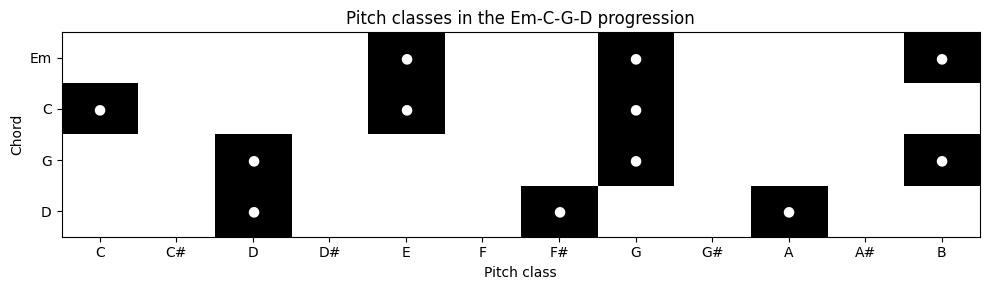

In [12]:
import matplotlib.pyplot as plt

pitch_class_matrix = np.zeros((len(progression), 12), dtype=int)

for i, chord in enumerate(chord_sets):
    for pitch_class in chord:
      pitch_class_matrix[i, pitch_class] = 1

fig, ax = plt.subplots(figsize=(10, 3))
ax.imshow(pitch_class_matrix, aspect="auto", cmap="Greys", vmin=0, vmax=1)
ax.set_xticks(range(12), NOTE_NAMES)
ax.set_yticks(range(len(chord_symbols)), chord_symbols)
ax.set_xlabel("Pitch class")
ax.set_ylabel("Chord")
ax.set_title("Pitch classes in the Em-C-G-D progression")
for i in range(len(chord_symbols)):
    for j in range(12):
        if pitch_class_matrix[i, j]:
            ax.text(j, i, "●", ha="center", va="center", color="white")

plt.tight_layout()
plt.show()

## 11. Interpretation and Limitations

**Observations to discuss after running the cells:**

1. The Em–C–G–D progression consists of four triads, each represented by three pitch classes.
2. The intersection operation counts pitch classes shared by consecutive chords.
3. In the tested cases, transposition preserves these shared-tone counts. The mathematical reason is that adding the same offset modulo 12 preserves equality between pitch classes.
4. The pitch-class matrix summarizes chord membership, but cannot represent which octave each note occupies.

**Limitations:** This model assumes 12-tone equal temperament and root-position major/minor triads. It does not represent rhythm, dynamics, inversions, voice leading, or harmonic function. Common-tone count alone cannot predict musical quality.

## 12. Sound Experiment: Hearing Mathematical Transpositions

### Research queation
How does adding a constant semitone offset differ from multiplyin semitone heights, both mathematically and audibly?

### Hypotheses

- **Transposition**: $T_k(\mathbf m)=\mathbf m+k\mathbf 1$ preserves adjacent semitone intervals: $D(T_k(\mathbf m))=D\mathbf m$.
- **Scaling** $S_a(\mathbf m)=a\mathbf m$ multiplies adjacent intervals: $D(S_a(\mathbf m))=aD\mathbf m$.

Here $\mathbf m=(0,4,7,9)$ contains integer semitone heights relative to **C4** (middle C), not frequencies. We use twelve-tone equal temperament (12-TET), with A4 = 440 Hz. The frequency for semitone height $n$ relative to C4 is

$$f(n)=440\cdot 2^{(n-9)/12}\;\mathrm{Hz}.$$

A single note is synthesized as a sinusoidal wave:

$$x(t)=A\sin(2\pi f t).$$

This simple model makes the pitch audible, but does not reproduce a real instrument's timbre. All notes are played at equal duration, so this experiment studies **pitch**, not rhythm or musical expressiveness.

In [13]:
from IPython.display import Audio, display

SAMPLE_RATE = 22050
NOTE_DURATION = 0.42 #seconds
AMPLITUDE = 0.25

# integer semitone heights relative to C4.
original = np.array([0, 4, 7, 9], dtype=int)
transposed = original + 5
scaled = original * 2

def semitone_to_frequency(height: int) -> float:
    """12-TET frequency in Hz, with height 0 = C4 and height 9 = A4."""
    return 440.0 * 2.0 ** ((int(height) - 9) / 12.0)

def note_label(height: int) -> str:
    """Pitch-class label plus octave number, relative to C4."""
    return f"{NOTE_NAMES[int(height) % 12]}{4 + int(height) // 12}"

def synthesize_note(height: int, duration: float = NOTE_DURATION) -> np.ndarray:
    """Generate a simple sine-wave note with short fades to avoid clicks."""
    count = int(SAMPLE_RATE * duration)
    t = np.arange(count) / SAMPLE_RATE
    wave = AMPLITUDE * np.sin(2 * np.pi * semitone_to_frequency(height) * t)
    fade_samples = min(int(0.015 * SAMPLE_RATE), count // 2)
    envelope = np.ones(count)
    if fade_samples:
        envelope[:fade_samples] = np.linspace(0, 1, fade_samples)
        envelope[-fade_samples:] = np.linspace(1, 0, fade_samples)
    return wave * envelope

def synthesize_melody(heights: np.ndarray) -> np.ndarray:
    """Concatenate equal-duration notes in sequence."""
    return np.concatenate([synthesize_note(int(h)) for h in heights])

versions = {
    "Original": original,
    "Transposed (+5 semitones)": transposed,
    "Scaled (×2 semitone heights)": scaled,
}

for title, heights in versions.items():
    print(f"{title}: {heights.tolist()}")
    print("Notes:", " – ".join(note_label(h) for h in heights))
    print("Intervals:", np.diff(heights).tolist())
    print("Frequencies (Hz):", [round(semitone_to_frequency(h), 1) for h in heights])
    display(Audio(synthesize_melody(heights), rate=SAMPLE_RATE, normalize=False))


Original: [0, 4, 7, 9]
Notes: C4 – E4 – G4 – A4
Intervals: [4, 3, 2]
Frequencies (Hz): [261.6, 329.6, 392.0, 440.0]


Transposed (+5 semitones): [5, 9, 12, 14]
Notes: F4 – A4 – C5 – D5
Intervals: [4, 3, 2]
Frequencies (Hz): [349.2, 440.0, 523.3, 587.3]


Scaled (×2 semitone heights): [0, 8, 14, 18]
Notes: C4 – G#4 – D5 – F#5
Intervals: [8, 6, 4]
Frequencies (Hz): [261.6, 415.3, 587.3, 740.0]


### Mathematical verification

Let $D$ be the adjacent-difference matrix from Section 3. Because $D\mathbf 1=\mathbf 0$,

$$D(\mathbf m+5\mathbf 1)=D\mathbf m+5D\mathbf 1=D\mathbf m.$$

But linearity gives

$$D(2\mathbf m)=2D\mathbf m.$$

Therefore, transposition preserves the **semitone interval pattern** $(4,3,2)$, whereas scaling changes it to $(8,6,4)$. Scaling semitone heights is **not** the same as making audio twice as loud or doubling all audio frequencies. In this coordinate system, it changes the pitch distances from the reference C4.

**Experimental Observations:**
After listening to the three melodies, I noticed that the scaled melody sounded higher and different from the original.

The mathematical results explain this observation:
*   Transposition (+5) preserves the original interval pattern (4, 3, 2).
*   Scaling (×2) changes the interval pattern to (8, 6, 4), creating larger jumps between consecutive notes.

This experiment demonstrates that transposition preserves relative semitone distances, while scaling semitone coordinates changes them.

The listening comparison supports the mathematical analysis, although the interval relationships are established by the calculations rather than by listening alone.

In [15]:
# Compare the original and transformed interval vectors.
assert np.array_equal(D @ original, [4, 3, 2])
assert np.array_equal(D @ transposed, D @ original)
assert np.array_equal(D @ scaled, 2 * (D @ original))
assert np.array_equal(D @ np.ones(4, dtype=int), np.zeros(3, dtype=int))

# Every +12 semitones doubles the frequency (one octave).
assert np.isclose(semitone_to_frequency(9), 440.0)
assert np.isclose(semitone_to_frequency(12), 2 * semitone_to_frequency(0))
print("All mathematical checks passed.")

All mathematical checks passed.


## 13. Trigonometry: Understanding Sound Waves


### Research question
How to frequency and amplitude change the shape of a pure musical tone?

A **pure tone** can be modeled by the sine function

$$x(t)=A\sin(2\pi ft+\phi),$$

where $t$ is time in seconds, $A$ is amplitude, $f$ is frequency in herts, and $\phi$ is the phase angle (radians). The sine function repeats after an angle of $2\pi$ radians, so its **period** is

$$T=\frac{1}{f}.$$

For A4, $f=440\,\mathrm{Hz}$ and $T=1/440\,\mathrm{s}\approx 2.273\,\mathrm{ms}$. Therefore, a 10 ms window contains approximately $4.4$ cycles.

**Hypothesis:** doubling the frequency halves the period; doubling the amplitude doubles the vertical size of the wave without changing its period.

The following graph shows the firs 10 milliseconds of a 440 Hz sine wave. The vertical axis is normalized signal amplitude, not a measurement of sound pressure in pascals.

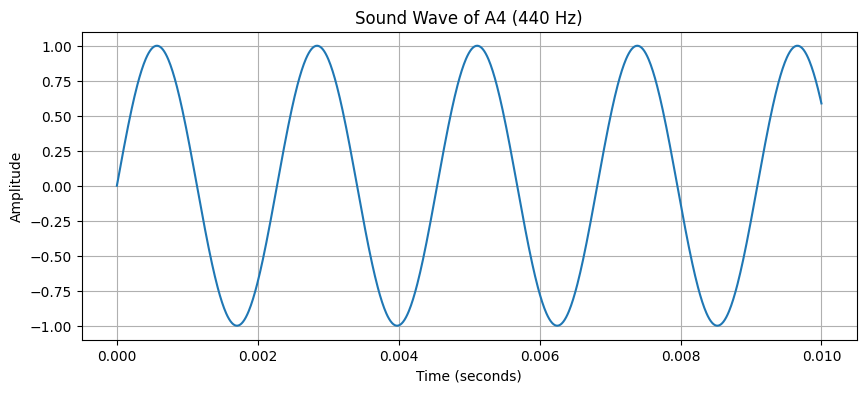

In [16]:
frequency = 440  # A4
amplitude = 1

# First 10 milliseconds
t = np.linspace(0, 0.01, 1000)

wave = amplitude * np.sin(2 * np.pi * frequency * t)

plt.figure(figsize=(10, 4))
plt.plot(t, wave)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Sound Wave of A4 (440 Hz)")
plt.grid(True)
plt.show()

### Experiment 13.1 - Frequency and amplitude comparison

Compare three sine waves over the **same time window**. A4 and A5 differ by one octave; the third signla has the same frequency as A4 but half its amplitude. Counting oscillations reveals frequency; measuring peak height reveals amplitude

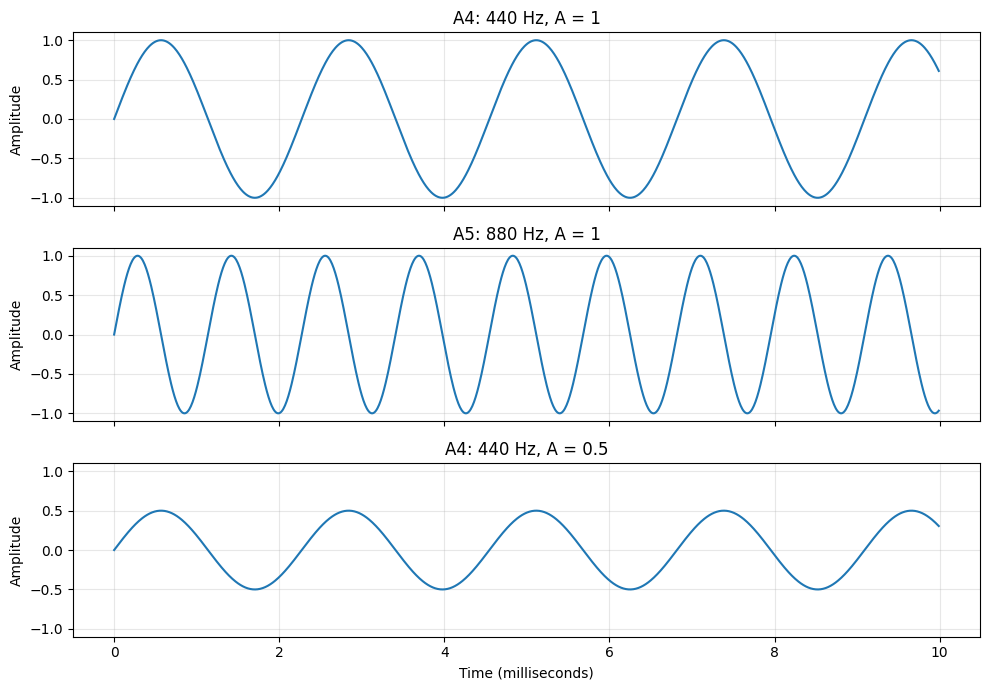

Trigonometry checks passed.


In [18]:
# Plot over a shared time axis to compare cycles and peak height.
plot_rate = 100_000
t_compare = np.arange(0, 0.01, 1 / plot_rate)

wave_a4 = np.sin(2 * np.pi * 440 * t_compare)
wave_a5 = np.sin(2 * np.pi * 880 * t_compare)
wave_quiet = 0.5 * np.sin(2 * np.pi * 440 * t_compare)

fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True, sharey=True)
for ax, values, label in zip(
    axes,
    [wave_a4, wave_a5, wave_quiet],
    ["A4: 440 Hz, A = 1", "A5: 880 Hz, A = 1", "A4: 440 Hz, A = 0.5"],
):
    ax.plot(t_compare * 1000, values)
    ax.set_title(label)
    ax.set_ylabel("Amplitude")
    ax.grid(True, alpha=0.3)
axes[-1].set_xlabel("Time (milliseconds)")
plt.tight_layout()
plt.show()

assert np.isclose(1 / 880, (1 / 440) / 2)
assert np.isclose(np.max(np.abs(wave_quiet)), 0.5 * np.max(np.abs(wave_a4)))
print("Trigonometry checks passed.")

### Interpretation

- A5 has approximately twice as many oscillations as A4 in the same time window, because its frequency is doubled.
- Halving $A$ halves the signal's amplitude but leaves the oscillation count unchanged.
- This model represents **pure tones**. Real instruments produce more complex waveforms with multiple frequency components.

**Connection to Section 12:** the pitch-height formula $f(n)=440\cdot2^{(n-9)/12}$ converts a semitone coordinate into the frequency used by the sine function.

## 14. Calculus: Derivatives of Sound Waves

### Research question
What does the derivative of a sound wave tell us about how the signal changes over time?

For the pure tone

$$x(t)=A\sin(2\pi ft),$$

the **first derivative with respect to time** is

$$\boxed{x'(t)=2\pi f A\cos(2\pi ft)}.$$

The derivative describes the **instantaneous rate of change of the signal** (signal-amplitude units per second). It is not the speed at which sound travels through air.

- At a peak or trough of $x(t)$, the slope is zero: $x'(t)=0$.
- At a zero crossing, the magnitude of the slope is greatest for this sine wave.
- Increasing $f$ while holding $A$ constant increases the maximum absolute slope, $2\pi f A$.

The second derivative is

$$x''(t)=-(2\pi f)^2 A\sin(2\pi ft)=-(2\pi f)^2x(t).$$

This is a differential-equation relationship for a sinusoid: its second derivative is proportional to the negative of the original signal.

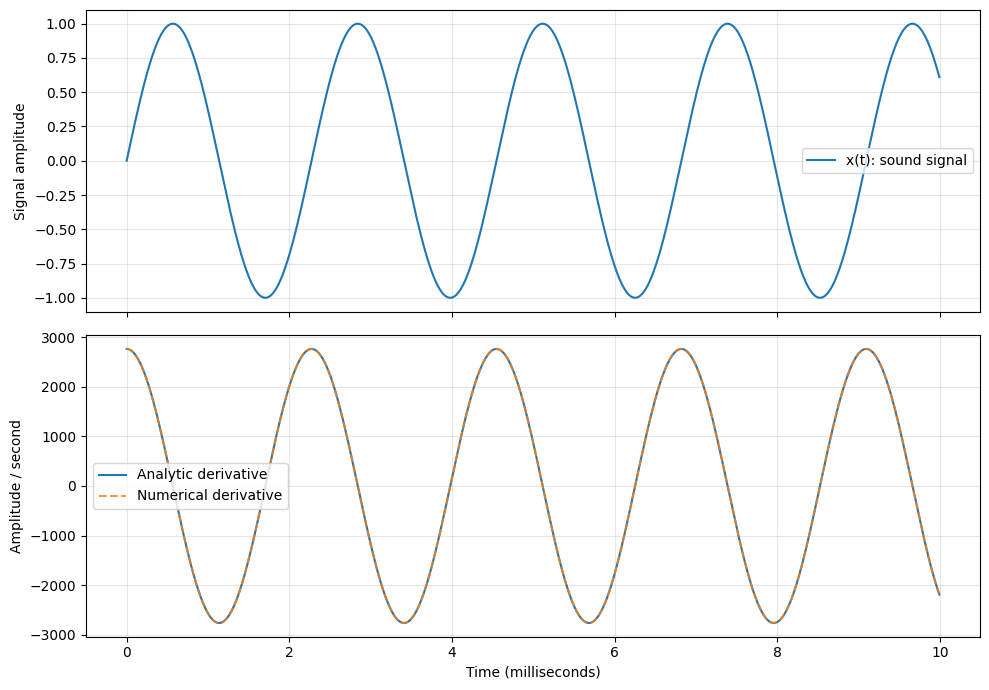

Maximum interior numerical derivative error: 0.352
Derivative comparison passed.


In [19]:
# Experiment 14.1: Compare the signal, analytic derivative and numerical derivative.
f = 440.0
A = 1.0
sample_rate_math = 100_000
t_calc = np.arange(0, 0.01, 1 / sample_rate_math)

x = A * np.sin(2 * np.pi * f * t_calc)
dx_exact = 2 * np.pi * f * A * np.cos(2 * np.pi * f * t_calc)
dx_numeric = np.gradient(x, t_calc)

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
axes[0].plot(t_calc * 1000, x, label="x(t): sound signal")
axes[0].set_ylabel("Signal amplitude")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(t_calc * 1000, dx_exact, label="Analytic derivative")
axes[1].plot(t_calc * 1000, dx_numeric, "--", label="Numerical derivative", alpha=0.8)
axes[1].set_xlabel("Time (milliseconds)")
axes[1].set_ylabel("Amplitude / second")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Numerical derivatives approximate the analytic derivative; finite step size causes error.
max_error = np.max(np.abs(dx_exact[1:-1] - dx_numeric[1:-1]))
print(f"Maximum interior numerical derivative error: {max_error:.3f}")
assert np.allclose(dx_exact[1:-1], dx_numeric[1:-1], rtol=0.001, atol=0.5)
print("Derivative comparison passed.")

### Experiment 14.2 — How frequency changes the slope

The maximum slope magnitude is $2\pi fA$. At fixed amplitude, doubling the frequency doubles this quantity, even though the **sound propagation speed** is unchanged.

In [21]:
for frequency in [220, 440, 880]:
    max_slope = 2 * np.pi * frequency * A
    print(f"f = {frequency:3d} Hz | period = {1000/frequency:.3f} ms | max |x'(t)| = {max_slope:.1f} amplitude/s")

assert np.isclose(2 * np.pi * 880 * A, 2 * (2 * np.pi * 440 * A))

# verify the second-derivative identity at sampled times.
d2x_exact = -(2 * np.pi * f)**2 * x
assert np.allclose(d2x_exact, -(2 * np.pi * f)**2 * x)
print("Calculus checks passed.")

f = 220 Hz | period = 4.545 ms | max |x'(t)| = 1382.3 amplitude/s
f = 440 Hz | period = 2.273 ms | max |x'(t)| = 2764.6 amplitude/s
f = 880 Hz | period = 1.136 ms | max |x'(t)| = 5529.2 amplitude/s
Calculus checks passed.


### Conclusions and limitations

**Trigonometry:** the frequency controls how quickly a sine wave repeats, while amplitude controls its vertical extent. The period is $T=1/f$.

**Calculus:** the first derivative describes the instantaneous change of the waveform; the second derivative of a sine wave is proportional to the negative of the original waveform. Numerical differentiation approximates the analytic result, with an error that depends on the sampling interval.

**Limitations:** these experiments use ideal sinusoidal tones and normalized amplitude. They do not model instrument timbre, acoustic loudness perception, air pressure calibration, or the physical speed of sound.

**Questions for further investigation:** How does adding a second sinusoid change the waveform? Can two tones have the same fundamental frequency but sound different? These questions lead toward harmonics and Fourier analysis.